# 10 · Newcomers and the rules (E5, E6)

**Experiments E5 and E6 of the project plan.** Two questions about the proposed design (the hybrid with fair re-ranking, notebook 06):

- **E5: do new members and new groups get a fair deal?** A recommender learns from what members did, so a member who just arrived, or a group
  nobody has joined yet, risks bad suggestions or never being shown. We measure both sides: how good the suggestions are for members with few
  groups or a new account, and how often new and small groups are shown and found. We compare today's BOING (biggest groups first), the hybrid,
  the proposed design and the default list (personalisation off, rule R1). The interim report also promised to check a side effect of R9
  (counting only established accounts) on newcomers: section 7.
- **E6: do the hard rules hold?** A separate program, `br.check_rules()`, checks every suggestion against the rules without trusting the code
  that made it: it recomputes every part of every score from the data, checks that each reason names the part that adds the most (R6,
  *explanation fidelity*), that no reason names a private, blocked or suspended account (R6, R8), the safety filters (R7, R8), the list length
  (R11, R1), and that private data and paid budgets change nothing (R2, R3). It runs on every member's list and at other dial settings, and we
  break a list on purpose to see that it notices.

Last, section 12 writes the **test cases** that BOING's JavaScript version of the recommender will be checked against.

Run notebooks 01, 02 and 06 first. The code shared by all notebooks is in `boingrec.py`, in this folder.

## 0 · Settings and data

The proposed design is `br.Config()` (chosen in notebooks 05 and 06). "No re-ranking" switches off the quota, the caps and diversity: that is the hybrid.

In [1]:
# Colab only: upload sim_v1.zip and sim_v1_split.zip (from notebooks 01 and 02) and boingrec.py (from the notebooks folder),
# all three at once. Locally this cell does nothing.
import sys, zipfile
from pathlib import Path
if 'google.colab' in sys.modules and not Path('boingrec.py').exists():
    from google.colab import files
    for fname in files.upload():
        if fname.endswith('.zip'):
            with zipfile.ZipFile(fname) as z:
                z.extractall('data')

In [2]:
import json
from dataclasses import asdict, replace
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import boingrec as br

SEED, K = br.SEED, br.K          # 0 and 5, the same in every notebook
br.use_style()
cfg = br.Config()                # the proposed design
NO_RERANK = dict(q=0, c=None, n=None, lam=1.0)
E5_METHODS = ['popularity', 'hybrid', 'reranked', 'off']
CONFIGS = {'hybrid': replace(cfg, **NO_RERANK), 'reranked': cfg, 'off': replace(cfg, personal=False)}

vis = br.load_visible()          # what a recommender may read: no test file, no hidden column
ans = br.load_answers()          # the answer key: only the scoring code reads it
tested = sorted(ans.test.user_id.unique())
gids = br.group_ids(vis)
name = vis.groups.set_index('group_id').name
created = vis.groups.set_index('group_id').created_day
stats = br.stats_for(vis, cfg)                    # statistics about other members (notebook 06)
clusters = br.topic_clusters(vis, cfg.clusters)   # public topic clusters (the same as recommend() makes)
print(f'{len(vis.train)} visible memberships, {len(ans.test)} hidden ones, {len(tested)} users to test')

6428 visible memberships, 1531 hidden ones, 1406 users to test


## 1 · Who is a newcomer?

- A **new member** joined BOING in the last 30 days (account created on day 336 or later; today is day 365). A member with **few groups** is in
  fewer than 3 groups in the training data.
- A **new group** was created in the last 30 days; a **small group** has fewer than 10 members in the training data. Together they are the
  "newcomer" groups that rule R4 gives at least 20% of the slots to. (The interim report counted day 335 too. No group was created on day
  335, so that gives the same 30 new groups; it would add 2 members, created on day 335, to the 300 new ones.)

**A problem with the test set:** it hides groups only of members who had 3 or more, so it holds 316 members with 2 groups left but **no new
member at all**, and only a handful of its hidden memberships are in new groups. So we add a **newcomer quiz**: every member who is not in the
test set (and not suspended) and is in at least one group gets one of their groups hidden, `br.newcomer_quiz()`. Nothing is tuned on it; it only
scores the settings already chosen. Members with one group are then left with **no group at all**: the true cold start.

In [3]:
qvis, quiz = br.newcomer_quiz(vis, tested)        # tested: only the scoring code knows who they are
quiz_users = sorted(quiz.user_id.unique())
qstats = br.stats_for(qvis, cfg)

n_train = vis.train.groupby('user_id').size()
n_quiz_left = qvis.train.groupby('user_id').size().reindex(quiz_users, fill_value=0)
joined_day = vis.users.set_index('user_id').created_day
is_new_member = lambda users: [u for u in users if joined_day[u] > br.TODAY - br.NEW_DAYS]
new_groups = set(created.index[created > br.TODAY - br.NEW_DAYS])
newcomer = br.newcomer_groups(vis)                 # new or small, as in every exposure number (E1)
small_older = newcomer - new_groups

SEGMENTS = {   # who -> (which quiz, which members); the last one overlaps the two before it
    '3 or more groups': ('test', [u for u in tested if n_train[u] >= 3]),
    '2 groups':         ('test', [u for u in tested if n_train[u] < 3]),
    '1 group':          ('quiz', [u for u in quiz_users if n_quiz_left[u] == 1]),
    'No group yet':     ('quiz', [u for u in quiz_users if n_quiz_left[u] == 0]),
    'New members':      ('quiz', is_new_member(quiz_users)),
}
counts = pd.DataFrame({
    'members': {who: len(users) for who, (_, users) in SEGMENTS.items()},
    'quiz': {who: where for who, (where, _) in SEGMENTS.items()},
    'new members among them': {who: len(is_new_member(users)) for who, (_, users) in SEGMENTS.items()}})
display(counts)
print(f'Test set: {len(is_new_member(tested))} new members; {ans.test.group_id.isin(new_groups).sum()} of its {len(ans.test)} hidden '
      f'memberships are in new groups, {ans.test.group_id.isin(newcomer).sum()} in new or small groups.')
print(f'Newcomer quiz: {len(quiz)} memberships hidden for {len(quiz_users)} members; {quiz.group_id.isin(new_groups).sum()} in new groups, '
      f'{quiz.group_id.isin(br.newcomer_groups(qvis)).sum()} in new or small groups.')
print(f'Groups: {len(new_groups)} new, {len(small_older)} older but small; {len(new_groups & set(br.discover_groups(vis.groups)))} new ones '
      f'are on Discover. The new groups have {vis.train.group_id.isin(new_groups).sum()} members in all (training data).')

,members,quiz,new members among them
3 or more groups,1090,test,0
2 groups,316,test,0
1 group,357,quiz,80
No group yet,122,quiz,122
New members,202,quiz,202


Test set: 0 new members; 8 of its 1531 hidden memberships are in new groups, 42 in new or small groups.
Newcomer quiz: 479 memberships hidden for 479 members; 1 in new groups, 14 in new or small groups.
Groups: 30 new, 37 older but small; 23 new ones are on Discover. The new groups have 37 members in all (training data).


In this fake community new groups have **hardly any members** besides their creator, and new members mostly join older groups: only 8 hidden
test memberships are in new groups. So "how often is a hidden membership in a new group found?" can only be answered with counts out of 8;
we add the broader question for new **or small** groups (about 40 hidden memberships).

## 2 · The four lists, for the test and for the newcomer quiz

Each method suggests 5 groups to each member, learning only from what it is allowed to see (for the quiz: the training data minus the quiz's
hidden memberships). The test lists are exactly those of experiment E1 (checked at the end).

In [4]:
def lists_for(v, st, users):
    # {method: {user_id: [5 group ids]}} and the recommend() tables (with reasons) for the three designs
    tables = {m: br.recommend(users, v, c, st, clusters=clusters) for m, c in CONFIGS.items()}
    lists = {'popularity': br.top_k(br.popularity_scores(v, users), v), **{m: br.lists_from(t) for m, t in tables.items()}}
    return lists, tables

test_lists, test_recs = lists_for(vis, stats, tested)
quiz_lists, quiz_recs = lists_for(qvis, qstats, quiz_users)
per_user = {('test', m): br.relevance_per_user(test_lists[m], ans.test) for m in E5_METHODS}
per_user |= {('quiz', m): br.relevance_per_user(quiz_lists[m], quiz) for m in E5_METHODS}
off_quiz = quiz_recs['reranked'].groupby('user_id').personal.first()
print(f'With personalisation on, {int((~off_quiz).sum())} of the {len(quiz_users)} quiz members have nothing to go on '
      f'(no group left and no public friend in a group) and get the default list.')

With personalisation on, 30 of the 479 quiz members have nothing to go on (no group left and no public friend in a group) and get the default list.


## 3 · Members: does a newcomer get good suggestions?

NDCG@5 and hit rate (does the list contain a hidden group?) for each kind of member, with a 95% range (bootstrap over members). The test and
the quiz are different quizzes (the quiz hides exactly one group, the test one or two), so compare methods within a column more than across.

In [5]:
rows = []
for who, (where, users) in SEGMENTS.items():
    for m in E5_METHODS:
        pu = per_user[(where, m)].loc[users]
        low, high = br.bootstrap_ci(pu['ndcg@5'])
        rows.append({'method': br.label(m), 'who': who, 'quiz': where, 'members': len(users), 'hit_rate': pu.hit_rate.mean(),
                     'ndcg@5': pu['ndcg@5'].mean(), 'ndcg@5 low': low, 'ndcg@5 high': high})
segments = pd.DataFrame(rows)
display(segments.pivot(index='method', columns='who', values='ndcg@5').loc[[br.label(m) for m in E5_METHODS], list(SEGMENTS)].round(3))
segments.pivot(index='method', columns='who', values='hit_rate').loc[[br.label(m) for m in E5_METHODS], list(SEGMENTS)].round(3)

who,3 or more groups,2 groups,1 group,No group yet,New members
method,,,,,
Popularity (today),0.132,0.127,0.160,0.150,0.134
Hybrid,0.562,0.468,0.431,0.332,0.353
Hybrid + fair re-ranking,0.546,0.465,0.400,0.326,0.343
Personalisation off,0.057,0.059,0.076,0.070,0.063


who,3 or more groups,2 groups,1 group,No group yet,New members
method,,,,,
Popularity (today),0.225,0.206,0.275,0.230,0.213
Hybrid,0.709,0.611,0.608,0.443,0.505
Hybrid + fair re-ranking,0.672,0.601,0.529,0.426,0.480
Personalisation off,0.098,0.098,0.123,0.123,0.109


**What re-ranking costs each kind of member.** The fair re-ranking gives some slots to new or small groups. Who pays for it? For each kind of
member: the hybrid's NDCG@5 minus the proposed design's, member by member, with a 95% range.

In [6]:
cost_rows = []
for who, (where, users) in SEGMENTS.items():
    diff = per_user[(where, 'hybrid')].loc[users, 'ndcg@5'] - per_user[(where, 'reranked')].loc[users, 'ndcg@5']
    low, high = br.bootstrap_ci(diff)
    cost_rows.append({'who': who, 'members': len(users), 'hybrid': per_user[(where, 'hybrid')].loc[users, 'ndcg@5'].mean(),
                      'proposed': per_user[(where, 'reranked')].loc[users, 'ndcg@5'].mean(), 'cost': diff.mean(),
                      'cost low': low, 'cost high': high, 'relative cost': diff.mean() / per_user[(where, 'hybrid')].loc[users, 'ndcg@5'].mean()})
cost = pd.DataFrame(cost_rows).set_index('who')
cost.round(4)

,members,hybrid,proposed,cost,cost low,cost high,relative cost
who,,,,,,,
3 or more groups,1090,0.5617,0.5464,0.0153,0.0101,0.0206,0.0272
2 groups,316,0.4682,0.4649,0.0033,-0.0065,0.0132,0.0070
1 group,357,0.4307,0.3997,0.0310,0.0185,0.0448,0.0720
No group yet,122,0.3323,0.3256,0.0067,0.0000,0.0169,0.0202
New members,202,0.3530,0.3430,0.0100,-0.0015,0.0224,0.0284


## 4 · Groups: are new and small groups shown, and found?

- **Shown:** the share of all slots in the tested members' lists that go to new groups, and to older groups that are small (as in E1).
- **Found:** of the hidden test memberships in new groups (and in new or small groups), how many are in the member's list.

In [7]:
def group_side(lists, truth, v):
    shown = [g for u in sorted(truth.user_id.unique()) for g in lists[u]]
    small = br.newcomer_groups(v) - new_groups
    in_new = truth[truth.group_id.isin(new_groups)]
    in_newcomer = truth[truth.group_id.isin(br.newcomer_groups(v))]
    found = lambda t: int(sum(g in lists[u] for u, g in zip(t.user_id, t.group_id)))
    return {'share new groups': np.mean([g in new_groups for g in shown]),
            'share older small groups': np.mean([g in small for g in shown]),
            'newcomer share': np.mean([g in br.newcomer_groups(v) for g in shown]),
            'found in new groups': found(in_new), 'hidden in new groups': len(in_new),
            'found in new or small groups': found(in_newcomer), 'hidden in new or small groups': len(in_newcomer)}

groups_test = pd.DataFrame({br.label(m): group_side(test_lists[m], ans.test, vis) for m in E5_METHODS}).T
groups_quiz = pd.DataFrame({br.label(m): group_side(quiz_lists[m], quiz, qvis) for m in E5_METHODS}).T
for t in [groups_test, groups_quiz]:
    t['recall new groups'] = t['found in new groups'] / t['hidden in new groups']
    t['recall new or small groups'] = t['found in new or small groups'] / t['hidden in new or small groups']
print('Test (the 1,406 tested members):')
display(groups_test.round(3))
print('Newcomer quiz:')
groups_quiz.round(3)

Test (the 1,406 tested members):


,share new groups,share older small groups,newcomer share,found in new groups,hidden in new groups,found in new or small groups,hidden in new or small groups,recall new groups,recall new or small groups
Popularity (today),0.000,0.000,0.000,0.0,8.0,0.0,42.0,0.000,0.000
Hybrid,0.004,0.016,0.020,1.0,8.0,8.0,42.0,0.125,0.190
Hybrid + fair re-ranking,0.042,0.161,0.203,1.0,8.0,14.0,42.0,0.125,0.333
Personalisation off,0.547,0.000,0.547,1.0,8.0,1.0,42.0,0.125,0.024


Newcomer quiz:


,share new groups,share older small groups,newcomer share,found in new groups,hidden in new groups,found in new or small groups,hidden in new or small groups,recall new groups,recall new or small groups
Popularity (today),0.000,0.000,0.000,0.0,1.0,0.0,14.0,0.0,0.000
Hybrid,0.054,0.007,0.061,1.0,1.0,2.0,14.0,1.0,0.143
Hybrid + fair re-ranking,0.086,0.152,0.238,0.0,1.0,3.0,14.0,0.0,0.214
Personalisation off,0.514,0.000,0.514,0.0,1.0,0.0,14.0,0.0,0.000


## 5 · The figure for the report

Top: how good the suggestions are for each kind of member (the bars' thin lines are 95% ranges; the proposed design's value is written on its bar).
Under each kind of member: how many there are, and which quiz scores them ("test" = the test set, "quiz" = the newcomer quiz).
Bottom: how much new and older small groups are shown, and how many hidden memberships in them are found (test).

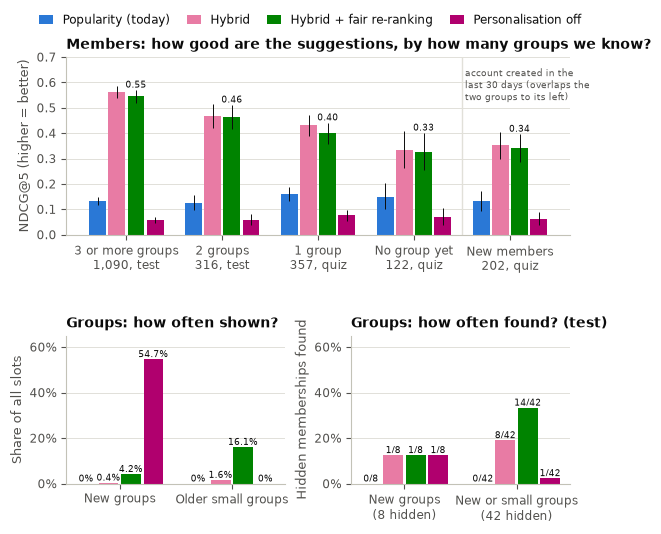

In [8]:
fig = plt.figure(figsize=(br.WIDTH, 5.4))
grid = fig.add_gridspec(2, 2, height_ratios=[1.2, 1], hspace=0.62, wspace=0.3, top=0.9)
ax_members, ax_shown, ax_found = fig.add_subplot(grid[0, :]), fig.add_subplot(grid[1, 0]), fig.add_subplot(grid[1, 1])
WIDTH_BAR = 0.8 / len(E5_METHODS)

def bars(ax, cats, value, text=None, err=None):
    # grouped bars: one group per category, one bar per method (always in E5_METHODS order and colour)
    x = np.arange(len(cats))
    for k, m in enumerate(E5_METHODS):
        xs = x - 0.4 + WIDTH_BAR * (k + 0.5)
        v = np.array([value(m, c) for c in cats])
        ax.bar(xs, v, WIDTH_BAR * 0.88, color=br.colour(m), label=br.label(m), zorder=2)   # 0.88: a thin white gap
        top = v.copy()
        if err is not None:
            lo, hi = np.array([err(m, c) for c in cats]).T
            ax.vlines(xs, lo, hi, color=br.INK, linewidth=0.7, zorder=3)
            top = hi
        if text is not None:
            for xi, ti, c in zip(xs, top, cats):
                label_ = text(m, c)
                if label_:
                    ax.text(xi, ti, label_, ha='center', va='bottom', fontsize=6.5, color=br.INK)
    ax.set_xticks(x)
    ax.grid(axis='y')

seg = segments.set_index(['method', 'who'])
cats = list(SEGMENTS)
bars(ax_members, cats, lambda m, c: seg.loc[(br.label(m), c), 'ndcg@5'],
     err=lambda m, c: seg.loc[(br.label(m), c), ['ndcg@5 low', 'ndcg@5 high']].to_numpy(),
     text=lambda m, c: f"{seg.loc[(br.label(m), c), 'ndcg@5']:.2f}" if m == 'reranked' else None)
ax_members.set_xticklabels([f'{c}\n{len(SEGMENTS[c][1]):,}, {SEGMENTS[c][0]}' for c in cats])
ax_members.axvline(3.5, color=br.GRID, linewidth=1)
ax_members.text(3.5, 0.66, ' account created in the\n last 30 days (overlaps the\n two groups to its left)', fontsize=6.5, color=br.MUTED,
                va='top', ha='left')
ax_members.set_ylim(0, 0.7)
ax_members.set_ylabel('NDCG@5 (higher = better)')
ax_members.set_title('Members: how good are the suggestions, by how many groups we know?')

shown_cats = ['share new groups', 'share older small groups']
bars(ax_shown, shown_cats, lambda m, c: groups_test.loc[br.label(m), c],
     text=lambda m, c: f'{100 * groups_test.loc[br.label(m), c]:.1f}%'.replace('.0%', '%'))
ax_shown.set_xticklabels(['New groups', 'Older small groups'])
ax_shown.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax_shown.set_ylim(0, 0.65)
ax_shown.set_ylabel('Share of all slots')
ax_shown.set_title('Groups: how often shown?')

found_cats = [('found in new groups', 'hidden in new groups'), ('found in new or small groups', 'hidden in new or small groups')]
bars(ax_found, found_cats, lambda m, c: groups_test.loc[br.label(m), c[0]] / groups_test.loc[br.label(m), c[1]],
     text=lambda m, c: f'{int(groups_test.loc[br.label(m), c[0]])}/{int(groups_test.loc[br.label(m), c[1]])}')
hidden_counts = groups_test.iloc[0][['hidden in new groups', 'hidden in new or small groups']].astype(int)
ax_found.set_xticklabels([f'New groups\n({hidden_counts.iloc[0]} hidden)', f'New or small groups\n({hidden_counts.iloc[1]} hidden)'])
ax_found.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax_found.set_ylim(0, 0.65)
ax_found.set_ylabel('Hidden memberships found')
ax_found.set_title('Groups: how often found? (test)')

handles, labels = ax_members.get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=4, bbox_to_anchor=(0.5, 1.0), handlelength=1.2, columnspacing=1.4)
br.save_fig(fig, 'e5_newcomers.png')
plt.show()

## 6 · Saving E5's numbers

`results/e5_newcomers.csv` has one row per method: NDCG@5 and hit rate for each kind of member, then the group side (shares of slots, hidden
memberships found). `results/e5_newcomers_detail.csv` has every number with its 95% range, and `results/e5_newcomers.json` the counts and what
re-ranking costs each kind of member.

In [9]:
short = {'3 or more groups': '3+ groups (test)', '2 groups': '2 groups (test)', '1 group': '1 group (quiz)',
         'No group yet': 'no group yet (quiz)', 'New members': 'new members (quiz)'}
wide = pd.DataFrame(index=[br.label(m) for m in E5_METHODS])
for who in SEGMENTS:
    wide[f'ndcg@5 {short[who]}'] = seg.xs(who, level='who')['ndcg@5']
    wide[f'hit {short[who]}'] = seg.xs(who, level='who')['hit_rate']
for m in E5_METHODS:
    pu = per_user[('test', m)]
    wide.loc[br.label(m), 'ndcg@5 all tested'] = pu['ndcg@5'].mean()
    wide.loc[br.label(m), 'hit all tested'] = pu.hit_rate.mean()
wide = wide.join(groups_test)
wide.index.name = 'method'
br.save_table(wide, 'e5_newcomers.csv')
detail = pd.concat([segments.assign(measure='members'),
                    groups_quiz.reset_index(names='method').assign(quiz='quiz', measure='groups'),
                    groups_test.reset_index(names='method').assign(quiz='test', measure='groups')], ignore_index=True)
br.save_table(detail.set_index(['measure', 'quiz', 'method']), 'e5_newcomers_detail.csv', decimals=4)
e5_summary = {
    'definitions': {'new member or group': f'created in the last {br.NEW_DAYS} days (day {br.TODAY - br.NEW_DAYS + 1} or later)',
                    'small group': f'fewer than {br.SMALL} members in the training data', 'few groups': 'fewer than 3 in the training data'},
    'members': {who: len(users) for who, (_, users) in SEGMENTS.items()},
    'test set new members': len(is_new_member(tested)),
    'quiz': {'memberships': len(quiz), 'members': len(quiz_users), 'default list (nothing to go on)': int((~off_quiz).sum())},
    'groups': {'new': len(new_groups), 'older small': len(small_older)},
    'cost of re-ranking per kind of member (hybrid minus proposed, NDCG@5)': cost.round(4).to_dict(orient='index'),
}
(br.RESULTS / 'e5_newcomers.json').write_text(json.dumps(e5_summary, indent=2), encoding='utf-8')
wide.round(3)

,ndcg@5 3+ groups (test),hit 3+ groups (test),ndcg@5 2 groups (test),hit 2 groups (test),ndcg@5 1 group (quiz),hit 1 group (quiz),ndcg@5 no group yet (quiz),hit no group yet (quiz),ndcg@5 new members (quiz),hit new members (quiz),...,hit all tested,share new groups,share older small groups,newcomer share,found in new groups,hidden in new groups,found in new or small groups,hidden in new or small groups,recall new groups,recall new or small groups
method,,,,,,,,,,,,,,,,,,,,,
Popularity (today),0.132,0.225,0.127,0.206,0.160,0.275,0.150,0.230,0.134,0.213,...,0.220,0.000,0.000,0.000,0.0,8.0,0.0,42.0,0.000,0.000
Hybrid,0.562,0.709,0.468,0.611,0.431,0.608,0.332,0.443,0.353,0.505,...,0.687,0.004,0.016,0.020,1.0,8.0,8.0,42.0,0.125,0.190
Hybrid + fair re-ranking,0.546,0.672,0.465,0.601,0.400,0.529,0.326,0.426,0.343,0.480,...,0.656,0.042,0.161,0.203,1.0,8.0,14.0,42.0,0.125,0.333
Personalisation off,0.057,0.098,0.059,0.098,0.076,0.123,0.070,0.123,0.063,0.109,...,0.098,0.547,0.000,0.547,1.0,8.0,1.0,42.0,0.125,0.024


## 7 · R9's side effect on newcomers

Rule R9 (resisting fake accounts) can count only accounts at level *L* or more, and count the joins of young accounts (created in the last 30 days)
at a lower weight. Both protect groups from a burst of fake accounts, but they also mute **real** new members: their joins then count less in
the group sizes and in "also joined", which may hurt new groups (joined by new members) and new members themselves. Experiment E4 (notebook 09)
measures the protection; here we measure the side effect, with the proposed design otherwise unchanged.

In [10]:
R9_SETTINGS = {'Proposed design (R9 off: L = 1)': cfg, 'Only level 3 or more counts (L = 3)': replace(cfg, L=3),
               'Young accounts count half (burst_w = 0.5)': replace(cfg, burst_w=0.5)}
levels = vis.users.set_index('user_id').level
print(f'{np.mean([levels[u] < 3 for u in is_new_member(vis.users.user_id)]):.0%} of new members are below level 3 '
      f'({np.mean(levels < 3):.0%} of all members).')
r9_rows = {}
for setting, c in R9_SETTINGS.items():
    t_lists = br.lists_from(br.recommend(tested, vis, c, br.stats_for(vis, c), clusters=clusters))
    q_lists = br.lists_from(br.recommend(quiz_users, qvis, c, br.stats_for(qvis, c), clusters=clusters))
    pt, pq = br.relevance_per_user(t_lists, ans.test), br.relevance_per_user(q_lists, quiz)
    side = group_side(t_lists, ans.test, vis)
    r9_rows[setting] = {'ndcg@5 all tested': pt['ndcg@5'].mean(), 'ndcg@5 2 groups (test)': pt.loc[SEGMENTS['2 groups'][1], 'ndcg@5'].mean(),
                        'ndcg@5 new members (quiz)': pq.loc[SEGMENTS['New members'][1], 'ndcg@5'].mean(),
                        'ndcg@5 no group yet (quiz)': pq.loc[SEGMENTS['No group yet'][1], 'ndcg@5'].mean(),
                        'share new groups': side['share new groups'], 'newcomer share': side['newcomer share'],
                        'found in new or small groups': side['found in new or small groups']}
r9 = pd.DataFrame(r9_rows).T
r9.index.name = 'setting'
br.save_table(r9, 'e5_r9.csv')
r9.round(3)

29% of new members are below level 3 (4% of all members).


,ndcg@5 all tested,ndcg@5 2 groups (test),ndcg@5 new members (quiz),ndcg@5 no group yet (quiz),share new groups,newcomer share,found in new or small groups
setting,,,,,,,
Proposed design (R9 off: L = 1),0.528,0.465,0.343,0.326,0.042,0.203,14.0
Only level 3 or more counts (L = 3),0.526,0.464,0.336,0.314,0.042,0.203,14.0
Young accounts count half (burst_w = 0.5),0.529,0.467,0.343,0.326,0.042,0.203,14.0


## 8 · E6: do the hard rules hold?

`br.check_rules(recs, data, config)` counts the violations of every rule in a set of suggestions. The table below lists its checks. Hard rules
must have **0** violations; the last three are dials (R4, R5) that the re-ranker may relax only when nothing else is possible, and then it says so.

To check reasons honestly it does **not** reuse the recommender's code: it recomputes every part of every score straight from the data tables
(its own "also joined", TF-IDF, AI model, friend counts and rescaling), and reads every fact a reason states (the group, the friend, the number)
back from the data. For R2 and R3 it reruns the recommender on copies of the data where every member also has made-up private data (planner
goals, coach chats, messages, purchases, wallet balance, tokens) and the answer key's hidden columns shuffled between members, or where one group
in five has paid for reach: not one suggestion may change.

We run it on every member's list (the 1,983 members who are not suspended; suspended accounts cannot log in), with the proposed design and with
personalisation off, and on the E1 test lists.

In [11]:
pd.DataFrame(br.RULE_CHECKS, index=['rule', 'a violation is', 'hard rule']).T

,rule,a violation is,hard rule
reason_parts,R6,"a part of the score, recomputed independently,...",True
reason_fidelity,R6,the reason is not faithful to the computed sco...,True
reason_details,R6,"the reason names the wrong group, friend or nu...",True
names_private,"R6, R8",a reason names a friend whose profile is private,True
names_blocked,"R6, R8","a reason names someone the member blocked, or ...",True
names_suspended,"R6, R8",a reason names a suspended account,True
names_other,"R6, R9",a reason names someone who is not a counted fr...,True
hidden_by_mods,R8,a group hidden by moderators is suggested,True
closed_group,R8,a closed group (not open to everyone) is sugge...,True
already_joined,R7,a group the member is already in is suggested,True


In [12]:
everyone = sorted(int(u) for u in vis.users.user_id[vis.users.suspended == 0])
runs, run_recs = {}, {}
run_recs['Proposed design, all members'] = (br.recommend(everyone, vis, cfg, stats, clusters=clusters), cfg, everyone, True)
run_recs['Personalisation off, all members'] = (br.recommend(everyone, vis, CONFIGS['off'], stats, clusters=clusters),
                                                CONFIGS['off'], everyone, True)
run_recs['Proposed design, tested members (E1)'] = (test_recs['reranked'], cfg, tested, False)
for run, (recs_, c, users, perturb) in run_recs.items():
    runs[run] = br.check_rules(recs_, vis, c, users=users, clusters=clusters, perturb=perturb, answers=ans)
rules_table = pd.DataFrame({run: t.violations for run, t in runs.items()})
rules_table.insert(0, 'rule', pd.Series({k: v[0] for k, v in br.RULE_CHECKS.items()}))
rules_table.insert(1, 'hard', pd.Series({k: v[2] for k, v in br.RULE_CHECKS.items()}))
print('Suggestions checked:', {run: int(t.loc['hidden_by_mods', 'checked']) for run, t in runs.items()})
print('Rules the re-ranker had to relax:', {run: r[0].attrs['relaxed'] for run, r in run_recs.items()})
rules_table

Suggestions checked: {'Proposed design, all members': 9915, 'Personalisation off, all members': 9915, 'Proposed design, tested members (E1)': 7030}
Rules the re-ranker had to relax: {'Proposed design, all members': {'quota': 0, 'topic cap': 0, 'global cap': 0}, 'Personalisation off, all members': {'quota': 0, 'topic cap': 0, 'global cap': 0}, 'Proposed design, tested members (E1)': {'quota': 0, 'topic cap': 0, 'global cap': 0}}


,rule,hard,"Proposed design, all members","Personalisation off, all members","Proposed design, tested members (E1)"
id,,,,,
reason_parts,R6,True,0,0,0.0
reason_fidelity,R6,True,0,0,0.0
reason_details,R6,True,0,0,0.0
names_private,"R6, R8",True,0,0,0.0
names_blocked,"R6, R8",True,0,0,0.0
names_suspended,"R6, R8",True,0,0,0.0
names_other,"R6, R9",True,0,0,0.0
hidden_by_mods,R8,True,0,0,0.0
closed_group,R8,True,0,0,0.0


(An empty cell means the check was not run: R2 and R3 rerun the recommender, so they run once per design, on all members.)

## 9 · Explanation fidelity (R6)

Every shown suggestion is one of three kinds: the reason names a part of the score (then it must be **the part that adds the most**, recomputed
independently); the slot was given by the newcomer quota (then it must say so, and the group must truly be new or small); or no part is above 0
(a member with very little to go on), and the reason states a true fact about the group (active, new, or small).

This measures whether each reason is **faithful to the computed score**. It is not the same as being factually true: here, with no privacy
noise, the two agree, but when the counts are clipped and noisy (R10) a faithful reason can quote an estimate that is wrong. Notebook 11 measures
that separately (`br.check_facts`, reading every reason against the raw data).

In [13]:
fid_rows = []
for run, t in runs.items():
    for kind, v in t.attrs['fidelity'].items():
        fid_rows.append({'run': run, 'kind': kind, 'shown': v['shown'], 'true': v['true']})
fidelity = pd.DataFrame(fid_rows)
fidelity['share true'] = fidelity['true'] / fidelity['shown'].where(fidelity['shown'] > 0)
display(fidelity.pivot(index='run', columns='kind', values='shown'))
total_shown = int(sum(t.loc['reason_fidelity', 'checked'] for t in runs.values()))
total_bad = int(sum(t.loc['reason_fidelity', 'violations'] for t in runs.values()))
top = fidelity[fidelity.kind == 'top part']
print(f'Explanation fidelity: {total_shown - total_bad:,} of {total_shown:,} reasons are true ({1 - total_bad / total_shown:.1%}); '
      f'of the {top.shown.sum():,} that name a part of the score, {top.true.sum() / top.shown.sum():.1%} name the part that adds the most.')
print('Mismatches:', 'none' if total_bad == 0 else '')
for t in runs.values():
    p = t.attrs['problems']
    if len(p):
        display(p.head(10))

kind,fallback,quota slot,top part
run,,,
"Personalisation off, all members",0,0,9915
"Proposed design, all members",44,1799,8072
"Proposed design, tested members (E1)",0,1288,5742


Explanation fidelity: 26,860 of 26,860 reasons are true (100.0%); of the 23,729 that name a part of the score, 100.0% name the part that adds the most.
Mismatches: none


An example: one member's five suggestions, with each part's contribution (as `recommend()` reports it) and the reason shown.

In [14]:
example = run_recs['Proposed design, all members'][0]
user = int(example[example.forced & example.personal].user_id.iloc[0])
show = example[example.user_id == user].assign(group=lambda d: d.group_id.map(name))
show[['rank', 'group', 'score', 'part_cf', 'part_content', 'part_social', 'part_mf', 'forced', 'reason_code', 'reason_text']].round(3)

,rank,group,score,part_cf,part_content,part_social,part_mf,forced,reason_code,reason_text
0,1,SAT prep squad,0.767,0.400,0.017,0.15,0.200,False,shared_members,85 members of Finals countdown are in it
1,2,30 days of Reading,0.572,0.243,0.000,0.15,0.179,False,shared_members,46 members of Journaling streak are in it
2,3,MCAT countdown,0.556,0.248,0.034,0.15,0.124,False,shared_members,49 members of Finals countdown are in it
3,4,Beat the IELTS,0.512,0.118,0.013,0.30,0.082,False,friend,Your friend user 68 and 1 other friend are mem...
4,5,GRE study hall,0.144,0.028,0.058,0.00,0.058,True,new_group,A small group: we show small groups so they ge...


## 10 · The rules at other dial settings

The final dials are chosen later (E2 to E5), so the hard rules must hold whatever they are. We rerun the checker on the tested members' lists at
other settings: two newcomer slots per list, no re-ranking at all, diversity on (MMR), the member's chosen topics counted (and a
descriptions-only mix, so that the "Matches a topic you picked" reason appears too), R9 on (fake-account defence), and R10 on (clipping, and
clipping with noise). R2 and R3 are rerun where the data the recommender reads changes (R9, R10).

In [15]:
SWEEP = {'q = 0.4 (two newcomer slots)': (replace(cfg, q=0.4), False),
         'No re-ranking (the hybrid)': (CONFIGS['hybrid'], False),
         'Diversity on (lam = 0.7)': (replace(cfg, lam=0.7), False),
         'Chosen topics count (topic_weight = 0.5)': (replace(cfg, topic_weight=0.5), False),
         'Descriptions only, topics count (beta = 1, topic_weight = 1)':
             (replace(cfg, alpha=0.0, beta=1.0, gamma=0.0, delta=0.0, topic_weight=1.0), False),
         'R9 on (L = 3, young accounts at half weight)': (replace(cfg, L=3, burst_w=0.5), True),
         'R10 clipping (m = 3)': (replace(cfg, m=3), False),
         'R10 clipping and noise (m = 5, eps = 1)': (replace(cfg, m=5, eps=1.0), True)}
sweep_rows = {}
codes_seen = set().union(*(set(r[0].reason_code) for r in run_recs.values()))   # which reason templates E6 has checked
for setting, (c, perturb) in SWEEP.items():
    recs_ = br.recommend(tested, vis, c, clusters=clusters)
    codes_seen |= set(recs_.reason_code)
    t = br.check_rules(recs_, vis, c, users=tested, clusters=clusters, perturb=perturb, answers=ans)
    sweep_rows[setting] = {'suggestions': int(t.loc['hidden_by_mods', 'checked']),
                           'hard-rule violations': int(t.violations[t.hard].sum()),
                           'checks run': int(t.violations.notna().sum()),
                           'fidelity': 1 - t.loc['reason_fidelity', 'violations'] / t.loc['reason_fidelity', 'checked'],
                           'reason codes': ', '.join(f'{k} {v}' for k, v in recs_.reason_code.value_counts().items()),
                           'dial checks passed': bool(t.passed[~t.hard].all()),
                           'relaxed': sum(recs_.attrs['relaxed'].values())}
sweep = pd.DataFrame(sweep_rows).T
sweep.index.name = 'setting'
print('Reason codes checked somewhere in E6:', sorted(codes_seen))
sweep

Reason codes checked somewhere in E6: ['active', 'friend', 'new_group', 'shared_members', 'similar_group', 'topic']


,suggestions,hard-rule violations,checks run,fidelity,reason codes,dial checks passed,relaxed
setting,,,,,,,
q = 0.4 (two newcomer slots),7030,0,18,1.0,"shared_members 3189, new_group 2718, friend 10...",True,0
No re-ranking (the hybrid),7030,0,18,1.0,"shared_members 4686, friend 2277, similar_grou...",True,0
Diversity on (lam = 0.7),7030,0,18,1.0,"shared_members 3740, friend 1922, new_group 12...",True,0
Chosen topics count (topic_weight = 0.5),7030,0,18,1.0,"shared_members 3951, friend 1735, new_group 12...",True,0
"Descriptions only, topics count (beta = 1, topic_weight = 1)",7030,0,18,1.0,"similar_group 6668, topic 278, new_group 84",True,0
"R9 on (L = 3, young accounts at half weight)",7030,0,20,1.0,"shared_members 3933, friend 1752, new_group 12...",True,0
R10 clipping (m = 3),7030,0,18,1.0,"shared_members 3624, friend 2044, new_group 12...",True,0
"R10 clipping and noise (m = 5, eps = 1)",7030,0,20,1.0,"shared_members 3581, friend 2155, new_group 10...",True,0


**A real problem the checker found.** With R9's down-weighting on (young accounts count half), the table of shared members holds
*weighted* counts. The first version of `recommend()` wrote that weighted number into the reason: "3 members of X are in it" when 4 members
truly are. That is not a true reason (R6). The checker compares the number with the members the two groups really share, so it caught this;
`recommend()` now states the true number when young accounts are down-weighted (and says "About" when clipping or noise is on, R10, where
the number is protected on purpose). Below we rebuild the old wording and count: the default design was never affected (it counts everyone fully).

In [16]:
c_burst = replace(cfg, burst_w=0.5)
stats_burst = br.stats_for(vis, c_burst)
fixed = br.recommend(tested, vis, c_burst, stats_burst, clusters=clusters)
old_wording = fixed.copy()
for i, r in old_wording[old_wording.reason_code == 'shared_members'].iterrows():
    n = int(round(stats_burst.co.loc[r.reason_ref, r.group_id]))           # the weighted count, as first written
    old_wording.loc[i, 'reason_text'] = (f'Members of {name[r.reason_ref]} also joined it' if n < 1 else
                                         f'{n} member{"s" if n > 1 else ""} of {name[r.reason_ref]} {"are" if n > 1 else "is"} in it')
wrong_before = int((old_wording.reason_text != fixed.reason_text).sum())
flagged = int(br.check_rules(old_wording, vis, c_burst, users=tested, clusters=clusters, perturb=False).loc['reason_details', 'violations'])
flagged_now = int(br.check_rules(fixed, vis, c_burst, users=tested, clusters=clusters, perturb=False).loc['reason_details', 'violations'])
print(f'With young accounts at half weight, the old wording got {wrong_before} of the {(fixed.reason_code == "shared_members").sum()} '
      f'"shared members" reasons wrong; the checker flags {flagged} of them. With the fix: {flagged_now}.')

With young accounts at half weight, the old wording got 916 of the 3941 "shared members" reasons wrong; the checker flags 916 of them. With the fix: 0.


## 11 · Does the checker notice a broken list?

Zero violations only means something if the checker would have found a problem. So we break the proposed design's test lists on purpose, **one
fault for every check** (20 checks, 26 faults: the block check gets one in each direction, the fidelity and private-data checks two), **one
fault at a time** (so that two faults never hide behind each other), and check that each is caught by the check meant for it. Most faults are
planted in the lists. Four are planted elsewhere, because their check looks elsewhere: the allow-list check (R2) is handed a table with a column
it must refuse; the private-data check (R2) and the paid-reach check (R3) are run against deliberately faulty recommenders, which read the answer
key's hidden interests, read the test file from disk, or boost groups that paid, whenever they can. (Besides altered copies of the data, the
private-data check reruns the recommender while the files it must never read, the test memberships and the full memberships, posts and likes, are
altered on the way in.) One fault is subtle: a group the member got on its own merit is passed off as a newcomer-quota slot, whose reason ("we
show new groups so they get a fair chance") would then skip the test of naming the largest part. The checker does not trust the recommender's
"quota slot" flag: it checks from the list itself that the quota could have given that slot.

The last three faults are planted in **the final design** (`br.FINAL_CONFIG`, notebook 11, noise draw 0), whose noise, R9 on friends and posts,
and "small" from the members who count take paths of the checker that notebook 06's design never takes: lists made with another noise draw than
the statistics report; young accounts counted as friends and posters; and "small" judged from the recommender's clipped, noisy counts.

In [17]:
good = test_recs['reranked']
member_groups = vis.train.groupby('user_id').group_id.apply(set)
people = vis.users.set_index('user_id')
gtab = vis.groups.set_index('group_id')
fair_text = lambda g: ('A new group: we show new groups so they get a fair chance' if g in new_groups
                       else 'A small group: we show small groups so they get a fair chance')
first = lambda t, mask: t.index[mask][0]
friend_text = lambda v: f'Your friend user {v} is a member'
allowed_mask = br.candidate_mask(vis, tested)                  # which groups each tested member may be shown

FAULTS = {   # id -> (the fault, the check meant to catch it)
    'hidden_group':    ('a group hidden by moderators is shown', 'hidden_by_mods'),
    'closed_group':    ('a closed group is shown', 'closed_group'),
    'joined_group':    ('a group the member is already in is shown', 'already_joined'),
    'dismissed_group': ('a group the member marked "not interested" is shown', 'not_interested'),
    'shown_twice':     ('the same group twice in one list', 'not_a_group'),
    'private_named':   ('a reason names a private profile', 'names_private'),
    'blocked_named':   ('a reason names someone the member blocked', 'names_blocked'),
    'blocker_named':   ('a reason names someone who blocked the member', 'names_blocked'),
    'suspended_named': ('a reason names a suspended account', 'names_suspended'),
    'stranger_named':  ("a reason names a public account that is not the member's friend", 'names_other'),
    'wrong_reason':    ('a reason that is not the largest part ("also joined" relabelled as the AI model)', 'reason_fidelity'),
    'fake_quota_slot': ('a group picked on its own merit passed off as a newcomer-quota slot', 'reason_fidelity'),
    'wrong_count':     ('a "shared members" reason with the wrong number of members', 'reason_details'),
    'wrong_part':      ('a part of the score reported 0.05 too high', 'reason_parts'),
    'short_list':      ('a list with 4 groups', 'list_length'),
    'empty_list':      ('a member with candidates gets no list at all', 'empty_list'),
    'quota_broken':    ("a list's only new or small group swapped for an ordinary one", 'quota'),
    'over_cap':        ('one group put in more lists than the global cap c allows', 'global_cap'),
    'topic_pile':      ('a list with three groups of one public topic cluster', 'topic_cap'),
    'extra_column':    ('the recommender is handed a column outside the allow-list (users.interests)', 'allow_list'),
    'reads_answers':   ('a recommender that reorders lists by the hidden interests when it can see them', 'private_data'),
    'paid_reach':      ('a recommender that moves groups that paid for reach to the top', 'paid_budget'),
    'reads_test_file': ("a recommender that reads the test file from disk and puts the member's hidden groups first", 'private_data'),
    # three faults in the final design (br.FINAL_CONFIG, noise draw 0), for the checker's paths that notebook 06's design never takes
    'final_noise_mismatch': ('final design: lists made with another noise draw than the one the statistics report', 'reason_parts'),
    'final_young_friend':   ('final design: young accounts counted as friends and in the activity (R9 on joins only)', 'names_other'),
    'final_small_counted':  ('final design: "small" judged from the clipped, noisy counts, not from the members who count', 'quota'),
}


def candidates_for(u, exclude=()):
    # groups member u may be shown (on Discover, not joined, not dismissed), minus `exclude`, in id order
    row = allowed_mask.loc[u]
    return [int(g) for g in row.index[row.to_numpy()] if int(g) not in set(exclude)]


def reorder(recs, key):
    # recs with each member's groups put in a new order (key(user, group) -> sort value, smallest first); ranks renumbered
    out = recs.assign(_k=[key(u, g) for u, g in zip(recs.user_id, recs.group_id)])
    out = out.sort_values(['user_id', '_k', 'rank'], kind='stable').drop(columns='_k')
    out['rank'] = out.groupby('user_id').cumcount() + 1
    out = out.reset_index(drop=True)
    out.attrs = dict(recs.attrs)
    return out


def faulty_recommender(kind):
    # A recommend() that cheats only when the data lets it: 'answers' reorders each list by the member's hidden top interest
    # (groups of that topic first), 'paid' puts the groups that paid for reach first. On the real data neither has anything to
    # read, so it gives the honest lists; on check_rules' altered copies it changes them. Returns (honest, faulty).
    honest = br.recommend
    def cheat(user_ids, data=br.DATA, config=None, stats=None, clusters=None):
        recs = honest(user_ids, data, config, stats, clusters)
        if kind == 'answers' and 'interests' in data.users.columns and 'topic' in data.groups.columns:
            top = data.users.set_index('user_id').interests.str.split(':').str[0]
            topic = data.groups.set_index('group_id').topic
            return reorder(recs, lambda u, g: 0 if topic[g] == top[u] else 1)
        if kind == 'paid' and 'boosted' in data.groups.columns:
            boosted = data.groups.set_index('group_id').boosted
            return reorder(recs, lambda u, g: -int(boosted[g]))
        if kind == 'test_file':
            # reads the answer key from disk (br.load_answers reads data/sim_v1/test_memberships.csv) and puts each member's hidden
            # groups first: the R2 test changes what that file holds on the way in, so the lists change
            hidden_ = set(zip(*br.load_answers().test[['user_id', 'group_id']].to_numpy().T))
            return reorder(recs, lambda u, g: 0 if (u, g) in hidden_ else 1)
        return recs
    return honest, cheat


FINAL = br.FINAL_CONFIG                                       # the final design (notebook 11), for the last three faults
cl_final = br.topic_clusters(vis, FINAL.clusters)
stats_final = br.stats_for(vis, FINAL)                        # its statistics, noise draw 0 (the draws the checker is told about)


def plant(fault):
    # The proposed design's test lists (and the data and recommender the checker is given) with ONE fault planted; the faults
    # named final_* plant it in the final design instead. Returns (lists, data, perturb, (honest, faulty) recommender or None,
    # the design the checker is told, its statistics, its clusters)
    bad, data, perturb, cheat = good.copy(), vis, False, None
    if fault.startswith('final_'):
        made_with = {'final_noise_mismatch': replace(FINAL, noise_seed=1),       # the lists use draw 1, the statistics say draw 0
                     'final_young_friend': replace(FINAL, r9_scope='joins'),     # young accounts count as friends and posters
                     'final_small_counted': replace(FINAL, small_from='counted')}[fault]   # "small" from the noisy counts
        bad = br.recommend(tested, vis, made_with, clusters=cl_final)
        return bad, vis, False, None, FINAL, stats_final, cl_final
    if fault == 'hidden_group':
        bad.loc[first(bad, bad['rank'] == 1), 'group_id'] = int(gtab.index[gtab.hidden_by_mods == 1][0])
    elif fault == 'closed_group':
        bad.loc[first(bad, bad['rank'] == 1), 'group_id'] = int(gtab.index[(gtab.open == 0) & (gtab.hidden_by_mods == 0)][0])
    elif fault == 'joined_group':
        i = first(bad, bad['rank'] == 2)
        bad.loc[i, 'group_id'] = min(member_groups[bad.loc[i, 'user_id']])
    elif fault == 'dismissed_group':
        ni = vis.not_interested[vis.not_interested.user_id.isin(tested)].iloc[0]
        bad.loc[first(bad, (bad.user_id == ni.user_id) & (bad['rank'] == 1)), 'group_id'] = int(ni.group_id)
    elif fault == 'shown_twice':
        mine = bad[bad.user_id == tested[5]].sort_values('rank')
        bad.loc[mine.index[-1], 'group_id'] = int(mine.group_id.iloc[0])
    elif fault in ('private_named', 'suspended_named'):
        v = int(people.index[(people.privacy == 'private') if fault == 'private_named' else (people.suspended == 1)][0])
        bad.loc[first(bad, bad.reason_code == 'friend'), ['reason_ref', 'reason_text']] = [v, friend_text(v)]
    elif fault in ('blocked_named', 'blocker_named'):
        member, other = ('user_id', 'blocked_id') if fault == 'blocked_named' else ('blocked_id', 'user_id')
        b = vis.blocks[vis.blocks[member].isin(tested)].iloc[0]
        bad.loc[first(bad, bad.user_id == b[member]), ['reason_code', 'reason_ref', 'reason_text']] = \
            ['friend', int(b[other]), friend_text(int(b[other]))]
    elif fault == 'stranger_named':
        i = first(bad, bad.reason_code == 'friend')
        u = int(bad.loc[i, 'user_id'])
        friends_u = set(vis.friendships.user_b[vis.friendships.user_a == u]) | set(vis.friendships.user_a[vis.friendships.user_b == u])
        v = int(people.index[(people.privacy == 'public') & (people.suspended == 0) & (people.level >= cfg.L)
                             & ~people.index.isin(list(friends_u) + [u])][0])
        bad.loc[i, ['reason_ref', 'reason_text']] = [v, friend_text(v)]
    elif fault == 'wrong_reason':
        i = first(bad, (bad.reason_code == 'shared_members') & (bad.part_cf > bad.part_mf))
        bad.loc[i, ['reason_code', 'reason_text']] = ['similar_group', f"Because you're in {name[bad.loc[i, 'reason_ref']]}"]
    elif fault == 'fake_quota_slot':
        i = first(bad, ~bad.forced & bad.group_id.isin(newcomer) & (bad['rank'] < K))
        bad.loc[i, ['forced', 'reason_code', 'reason_text', 'reason_ref']] = [True, 'new_group', fair_text(bad.loc[i, 'group_id']), 0]
    elif fault == 'wrong_count':
        i = first(bad, (bad.reason_code == 'shared_members') & bad.reason_text.str.match(r'\d+ members? of'))
        n = int(bad.loc[i, 'reason_text'].split(' ')[0])
        bad.loc[i, 'reason_text'] = f'{n + 1} members of ' + bad.loc[i, 'reason_text'].split(' of ', 1)[1]
    elif fault == 'wrong_part':
        bad.loc[first(bad, ~bad.forced), 'part_cf'] += 0.05
    elif fault == 'short_list':
        bad = bad.drop(index=bad.index[bad.user_id == tested[3]][-1:])
    elif fault == 'empty_list':
        bad = bad[bad.user_id != tested[4]]
    elif fault == 'quota_broken':
        per = bad.assign(nc=bad.group_id.isin(newcomer)).groupby('user_id').nc.sum()
        u = int(per.index[per == 1][0])                                        # a member whose list holds exactly one
        mine = bad[bad.user_id == u]
        i = mine.index[mine.group_id.isin(newcomer)][0]
        bad.loc[i, 'group_id'] = [g for g in candidates_for(u, mine.group_id) if g not in newcomer][0]
    elif fault == 'over_cap':
        g = int(bad.group_id.value_counts().index[0])                          # the most-shown group, pushed past the cap
        cap = max(1, int(np.floor(cfg.c * K * len(tested) + 1e-9)))
        extra = (cap - int((bad.group_id == g).sum())) + 10
        idx = [first(bad, (bad.user_id == u) & (bad['rank'] == K)) for u in tested
               if g in candidates_for(u) and g not in set(bad.group_id[bad.user_id == u])][:extra]
        bad.loc[idx, 'group_id'] = g
    elif fault == 'topic_pile':
        mine = bad[bad.user_id == tested[7]].sort_values('rank')
        options = pd.Series({g: clusters[g] for g in candidates_for(tested[7])})
        cl = options.value_counts().index[0]                                   # the cluster with the most candidates
        pile = [g for g in options.index[options == cl] if g not in set(mine.group_id)][:3]
        bad.loc[mine.index[-3:], 'group_id'] = pile
    elif fault == 'extra_column':
        data = replace(vis, users=vis.users.assign(interests=ans.user_interests.reindex(vis.users.user_id).to_numpy()))
    elif fault in ('reads_answers', 'paid_reach'):
        perturb, cheat = True, faulty_recommender('answers' if fault == 'reads_answers' else 'paid')
    elif fault == 'reads_test_file':
        perturb, cheat = True, faulty_recommender('test_file')
        bad = cheat[1](tested, vis, cfg, clusters=clusters)     # its lists on the real files (it cheats there too)
    return bad, data, perturb, cheat, cfg, None, clusters


caught_rows = []
for f, (what, check) in FAULTS.items():
    bad, data, perturb, cheat, c_, stats_, cl_ = plant(f)
    if cheat is not None:
        br.recommend = cheat[1]                     # the checker reruns the recommender: here, the faulty one
    try:
        t = br.check_rules(bad, data, c_, users=tested, stats=stats_, clusters=cl_, perturb=perturb, answers=ans)
    finally:
        if cheat is not None:
            br.recommend = cheat[0]                 # always put the honest recommender back
    fired = t.violations[t.violations > 0]
    caught_rows.append({'fault': what, 'check meant to catch it': check, 'violations found': int(t.loc[check, 'violations']),
                        'caught': bool(t.loc[check, 'violations'] > 0), 'every check that fired': ', '.join(fired.index)})
caught = pd.DataFrame(caught_rows, index=pd.Index(list(FAULTS), name='id'))
assert br.recommend.__name__ == 'recommend', 'the honest recommender is back'
every_check_tested = set(caught['check meant to catch it']) == set(br.RULE_CHECKS)
print(f'{int(caught.caught.sum())} of {len(caught)} planted faults caught by the check meant for them; '
      f'every one of the {len(br.RULE_CHECKS)} checks has a fault of its own: {every_check_tested}.')
caught

26 of 26 planted faults caught by the check meant for them; every one of the 20 checks has a fault of its own: True.


,fault,check meant to catch it,violations found,caught,every check that fired
id,,,,,
hidden_group,a group hidden by moderators is shown,hidden_by_mods,1,True,"reason_parts, reason_fidelity, reason_details,..."
closed_group,a closed group is shown,closed_group,1,True,"reason_parts, reason_fidelity, reason_details,..."
joined_group,a group the member is already in is shown,already_joined,1,True,"reason_parts, reason_fidelity, reason_details,..."
dismissed_group,"a group the member marked ""not interested"" is ...",not_interested,1,True,"reason_parts, reason_fidelity, reason_details,..."
shown_twice,the same group twice in one list,not_a_group,1,True,"reason_parts, reason_fidelity, reason_details,..."
private_named,a reason names a private profile,names_private,1,True,"reason_details, names_private, names_other"
blocked_named,a reason names someone the member blocked,names_blocked,1,True,"reason_details, names_private, names_blocked, ..."
blocker_named,a reason names someone who blocked the member,names_blocked,1,True,"reason_fidelity, reason_details, names_blocked..."
suspended_named,a reason names a suspended account,names_suspended,1,True,"reason_details, names_suspended, names_other"


## 12 · Test cases for BOING's JavaScript port

The plan: the recommender is rebuilt in JavaScript inside BOING's test copy, and must give **the same answers** on small test cases (that match
is itself a result for the report). `br.make_test_cases(config)` writes them into `testcases/`: each case is a folder with a small community (100
members, 20 groups, the same columns as `data/sim_v1` minus the hidden ones), its `config.json`, the expected 5 suggestions of every member with
score and reason (`expected.csv`), and a `README.md` saying what it checks. Cases 01 to 11 start from the same small community and change one
thing. Its 18 Discover groups make the global cap bind, so case 12 adds a larger world (300 members of the synthetic community, 150 groups) where
no rule is relaxed, and case 13 turns the privacy noise on there, with the draws given as data (`noise.csv`) so a port can add exactly the same
numbers. Elsewhere the noise is off (`eps = None`) so every number is exact. When the final dials are chosen, one call regenerates them all.

`br.verify_test_cases()` then reruns every case from its own files only, compares with `expected.csv`, and runs the rule checker on it.

In [18]:
case_index = br.make_test_cases(cfg)
verify = br.verify_test_cases()
pd.set_option('display.max_colwidth', 120)
display(case_index[['checks', 'members', 'rows', 'intent_holds', 'hard_rule_violations']])
verify

,checks,members,rows,intent_holds,hard_rule_violations
case,,,,,
01_ordinary_member,"An ordinary member: user 1 (in Spanish for beginners, Spanish evening chat and Python project club, with public frie...",100,500,True,0
02_cold_start_member,"Cold start: user 1 is in one group only (Spanish for beginners) and has no friends; they still get 5 suggestions, an...",100,500,True,0
03_brand_new_group,A brand-new group: Spanish for travellers (group 17) was created 2 days ago and has 3 members; in user 1's list it t...,100,500,True,0
04_hidden_by_moderators,"Hidden by moderators: Daily Python (group 6), user 1's first suggestion when it is visible, is hidden; it must never...",100,500,True,0
05_blocked_friend,"Blocks: user 1 blocked user 6, and user 10 blocked user 1; both are user 1's friends and were named in user 1's reas...",100,500,True,0
06_private_friend,"A private profile: user 6, user 1's friend named in a reason before, switches to a private profile; no reason may na...",100,500,True,0
07_not_interested,"Not interested: user 1 marked Daily Python (group 6), their first suggestion before, ""not interested""; it must not c...",100,500,True,0
08_accounts_that_do_not_count,Accounts that must not count: 4 suspended accounts (users 101-104) and 4 level-1 accounts (users 105-108) joined Spa...,108,520,True,0
09_almost_everything_joined,"Almost everything joined: user 1 is in every Discover group but 3 (groups 9, 14 and 17); the list must hold exactly ...",100,498,True,0


,rows,matches_expected,same_serve_order,hard_rule_violations
case,,,,
01_ordinary_member,500,True,True,0
02_cold_start_member,500,True,True,0
03_brand_new_group,500,True,True,0
04_hidden_by_moderators,500,True,True,0
05_blocked_friend,500,True,True,0
06_private_friend,500,True,True,0
07_not_interested,500,True,True,0
08_accounts_that_do_not_count,520,True,True,0
09_almost_everything_joined,498,True,True,0


Case 03, for example: a group created 2 days ago takes member 1's newcomer slot.

In [19]:
expected = pd.read_csv(br.TESTCASES / '03_brand_new_group' / 'expected.csv')
expected[expected.user_id == 1]

,user_id,rank,group_id,score,reason_code,reason_text
0,1,1,6,0.843571,shared_members,11 members of Python project club are in it
1,1,2,13,0.826896,friend,Your friend user 6 and 3 other friends are members
2,1,3,4,0.772473,shared_members,8 members of Spanish evening chat are in it
3,1,4,3,0.731638,shared_members,6 members of Spanish for beginners are in it
4,1,5,17,0.510846,new_group,A new group: we show new groups so they get a fair chance


## 13 · Saving E6's numbers

`results/e6_rules.json`: for each run, each check's violation count and pass/fail; the explanation fidelity; the other dial settings; the
deliberate faults; and the test cases.

In [20]:
def run_summary(t):
    return {'checks': {cid: {'rule': row.rule, 'hard': bool(row.hard), 'checked': int(row.checked),
                             'violations': None if pd.isna(row.violations) else int(row.violations),
                             'passed': None if row.passed is None else bool(row.passed)} for cid, row in t.iterrows()},
            'hard_violations': int(t.violations[t.hard].sum()),
            'fidelity': t.attrs['fidelity']}

e6 = {
    'runs': {run: {'members': len(users), 'suggestions': int(runs[run].loc['hidden_by_mods', 'checked']),
                   'relaxed': recs_.attrs['relaxed'], **run_summary(runs[run])}
             for run, (recs_, c, users, perturb) in run_recs.items()},
    'explanation_fidelity': {'reasons': int(total_shown), 'true': int(total_shown - total_bad), 'share': float(1 - total_bad / total_shown),
                             'name the largest part': int(top.true.sum()), 'name a part': int(top.shown.sum())},
    'dial_settings': sweep_rows,
    'checker_catches_faults': {f: {'fault': row.fault, 'check': row['check meant to catch it'],
                                   'violations found': int(row['violations found']), 'caught': bool(row.caught),
                                   'every check that fired': row['every check that fired']} for f, row in caught.iterrows()},
    'found_and_fixed': {'problem': 'with young accounts down-weighted (burst_w < 1), "N members of X are in it" stated a weighted count',
                        'setting': 'burst_w = 0.5, tested members', 'wrong reasons before the fix': wrong_before,
                        'flagged by the checker': flagged, 'flagged after the fix': flagged_now},
    'test_cases': {'cases': len(case_index), 'match_expected': int(verify.matches_expected.sum()),
                   'intent_holds': int(case_index.intent_holds.sum()), 'hard_rule_violations': int(case_index.hard_rule_violations.sum()),
                   'folder': 'testcases/'},
}
e6['all_hard_rules_hold'] = (all(r['hard_violations'] == 0 for r in e6['runs'].values())
                             and all(s['hard-rule violations'] == 0 for s in e6['dial_settings'].values()))
plain = lambda o: o.item() if hasattr(o, 'item') else str(o)          # numpy numbers -> plain numbers for JSON
(br.RESULTS / 'e6_rules.json').write_text(json.dumps(e6, indent=2, default=plain), encoding='utf-8')
print(json.dumps({k: e6[k] for k in ['explanation_fidelity', 'test_cases', 'all_hard_rules_hold']}, indent=2))

{
  "explanation_fidelity": {
    "reasons": 26860,
    "true": 26860,
    "share": 1.0,
    "name the largest part": 23729,
    "name a part": 23729
  },
  "test_cases": {
    "cases": 13,
    "match_expected": 13,
    "intent_holds": 13,
    "hard_rule_violations": 0,
    "folder": "testcases/"
  },
  "all_hard_rules_hold": true
}


## 14 · Checks

In [21]:
e1 = pd.read_csv(br.RESULTS / 'e1_methods.csv', index_col=0)
E1_COLS = [c for c in e1.columns if c != 'users']
quiz_again = br.newcomer_quiz(vis, tested)[1]
test_pairs = set(zip(ans.test.user_id, ans.test.group_id))
checks = {
    'the test lists are E1\'s: the same relevance and exposure for the four methods (e1_methods.csv)':
        all(np.allclose(br.evaluate(test_lists[m], ans.test, vis, ans.group_topic)[E1_COLS].astype(float).round(3),
                        e1.loc[br.label(m), E1_COLS].astype(float), rtol=0, atol=1e-9) for m in E5_METHODS),
    'the kinds of members split the tested members (2 groups + 3 or more = 1,406) and the quiz members':
        len(SEGMENTS['2 groups'][1]) + len(SEGMENTS['3 or more groups'][1]) == len(tested)
        and len(SEGMENTS['1 group'][1]) + len(SEGMENTS['No group yet'][1]) == len(quiz_users)
        and all(n_train[u] == 2 for u in SEGMENTS['2 groups'][1]),
    'the newcomer quiz never touches the test: no tested or suspended member, one hidden group each, none left visible':
        not set(quiz_users) & set(tested) and quiz.groupby('user_id').size().eq(1).all()
        and not set(zip(quiz.user_id, quiz.group_id)) & set(zip(qvis.train.user_id, qvis.train.group_id))
        and not set(quiz_users) & set(vis.users.user_id[vis.users.suspended == 1])
        and not test_pairs & set(zip(qvis.train.user_id, qvis.train.group_id)),
    'same seed, same quiz: newcomer_quiz() run again gives the same hidden memberships': quiz_again.equals(quiz),
    'R4 holds for newcomers: the proposed design gives new or small groups at least q of the slots (test and quiz)':
        groups_test.loc[br.label('reranked'), 'newcomer share'] >= cfg.q and groups_quiz.loc[br.label('reranked'), 'newcomer share'] >= cfg.q,
    'E6: no hard rule is broken, in any run or at any dial setting': e6['all_hard_rules_hold'],
    'E6: the dials hold wherever the re-ranker did not have to relax them':
        all(bool(t.passed[~t.hard].dropna().all()) for t in runs.values()) and sweep['dial checks passed'].all(),
    'E6: explanation fidelity is 100% (every reason is faithful to the computed score: the largest part, a quota slot, or the fallback fact)':
        total_bad == 0,
    'E6: R2 and R3 were tested (private data and paid budgets change no suggestion)':
        all(runs[r].loc[c, 'checked'] > 0 and runs[r].loc[c, 'violations'] == 0
            for r in ['Proposed design, all members', 'Personalisation off, all members'] for c in ['private_data', 'paid_budget']),
    'E6: the personalisation-off list is never empty and always has 5 groups when 5 are possible':
        runs['Personalisation off, all members'].loc[['empty_list', 'list_length'], 'violations'].sum() == 0,
    'E6: every reason template was checked somewhere (shared members, similar group, friend, topic, new group, active)':
        {'shared_members', 'similar_group', 'friend', 'topic', 'new_group', 'active'} <= codes_seen,
    'E6: the checker catches every deliberate fault, and every one of its checks has a fault of its own': caught.caught.all() and every_check_tested,
    'E6: the honest recommender was put back after the faulty ones': br.recommend.__name__ == 'recommend',
    'E6: the numbers written in the text are this run\'s (26 faults, 20 checks, 13 test cases)':
        len(caught) == 26 and len(br.RULE_CHECKS) == 20 and len(case_index) == 13,
    'E6: the checker flags every reason the old wording got wrong under R9\'s down-weighting, and none after the fix':
        wrong_before > 0 and flagged == wrong_before and flagged_now == 0,
    'test cases: about 10, each rerun from its own files gives exactly expected.csv':
        len(case_index) >= 10 and verify.matches_expected.all() and verify.same_serve_order.all(),
    'test cases: each shows what it is meant to show, with no hard-rule violation':
        case_index.intent_holds.all() and (case_index.hard_rule_violations == 0).all() and (verify.hard_rule_violations == 0).all(),
    'a recommender never gets a hidden column or a test membership':
        not {'interests', 'is_fake'} & set(vis.users.columns) and 'topic' not in vis.groups.columns
        and not set(zip(vis.train.user_id, vis.train.group_id)) & test_pairs,
}
for check, ok_ in checks.items():
    print('✓' if ok_ else '✗', check)
assert all(checks.values()), 'Some checks failed (see ✗ above)'

✓ the test lists are E1's: the same relevance and exposure for the four methods (e1_methods.csv)
✓ the kinds of members split the tested members (2 groups + 3 or more = 1,406) and the quiz members
✓ the newcomer quiz never touches the test: no tested or suspended member, one hidden group each, none left visible
✓ same seed, same quiz: newcomer_quiz() run again gives the same hidden memberships
✓ R4 holds for newcomers: the proposed design gives new or small groups at least q of the slots (test and quiz)
✓ E6: no hard rule is broken, in any run or at any dial setting
✓ E6: the dials hold wherever the re-ranker did not have to relax them
✓ E6: explanation fidelity is 100% (every reason is faithful to the computed score: the largest part, a quota slot, or the fallback fact)
✓ E6: R2 and R3 were tested (private data and paid budgets change no suggestion)
✓ E6: the personalisation-off list is never empty and always has 5 groups when 5 are possible
✓ E6: every reason template was checked som

## What we learned

**E5: new members and new groups**

- **The test set alone cannot answer E5.** It holds no new member (it only hides groups of members who had 3 or more) and only 8 hidden
  memberships in new groups. The newcomer quiz (479 members with 1 or 2 groups, 202 of them new) fills the first gap. The second comes from
  this fake community: its 30 new groups have 37 members in all, mostly their creators.
- **Members: the less we know, the worse the suggestions, but the design helps newcomers too.** The proposed design's NDCG@5 falls from
  **0.55** (3 or more groups) to **0.46** (2 groups), **0.40** (1 group) and **0.33** (no group yet: only public friends to go on), and is
  **0.34** for new members. Today's BOING gets 0.13 to 0.16 at every level. Even a member with no group gets twice today's quality
  (hit rate 43% against 23%). Only 30 of the 479 quiz members have nothing at all to go on, and they get the default list.
- **The default list (personalisation off, R1) is what a new member sees until they switch personalisation on:** NDCG@5 0.06 to 0.08,
  below today's popularity list. It is generous to new groups (55% of its slots) but weak for the member: the price of R1's privacy default,
  and a reason to make the switch easy to find.
- **Who pays for fair re-ranking:** 0.015 NDCG@5 for members with 3 or more groups (2.7%), and **0.031 for members with one group**
  (7.2%, 95% range 0.019 to 0.045): the newcomer slot replaces one of the few good suggestions they have. For members with 2 groups, no
  group, or a new account the cost is at most 0.01, too small to tell from 0.
- **Groups:** the proposed design gives new groups **4.2%** of all slots (hybrid 0.4%, today 0%) and older small groups **16.1%** (hybrid
  1.6%). It finds **14 of the 42** hidden test memberships in new or small groups (hybrid 8, today 0, default list 1). Of the 8 in new
  groups, at most 1 is found, whatever the design: a group with almost no members has little to be matched on but its description.
- **R9's side effect on newcomers is small:** counting only accounts at level 3 or more (29% of new members are below it) lowers new
  members' NDCG@5 from 0.343 to 0.336 and no-group members' from 0.326 to 0.314; counting young accounts at half weight changes nothing
  measurable. The exposure of new groups does not change.

**E6: the hard rules hold**

- **0 violations of every hard rule**, on every member's list (1,983 members, 9,915 suggestions) with the proposed design and with
  personalisation off, on the E1 test lists, and at 8 other dial settings (two newcomer slots, no re-ranking, diversity on, chosen topics,
  descriptions only, R9 on, R10 clipping, R10 clipping with noise). No reason names a private, blocked or suspended account; no hidden,
  closed, joined or "not interested" group is shown; every list has 5 groups; the default list is never empty. Adding made-up private
  data (planner, coach chats, wallet...), the shuffled answer key, altered copies of the files a recommender must never read (test
  memberships, full memberships, posts and likes), or paid budgets changed **not one** suggestion (R2, R3).
- **Explanation fidelity is 100%: every reason is faithful to the computed score.** All **26,860** reasons checked name what the
  recommender computed: the 23,729 that name a part of the score all name the part that adds the most (recomputed independently); 3,087 are
  quota slots that say so and 44 state the fact used when no part is above 0. Faithful is not the same as true: with clipping and noise
  (R10) the score rests on estimates, so notebook 11 also reads every reason against the raw data (`br.check_facts`).
- **The checker works:** it caught each of the 26 faults we planted one at a time, at least one for each of its 20 checks (hidden, closed,
  joined, dismissed and duplicated groups shown; a private, blocked (both ways), suspended or unrelated account named; a reason that is not
  the largest part; a group passed off as a newcomer-quota slot; a wrong count in a reason; a wrong part; a short and an empty list; a list
  without its newcomer group, over the global cap, or with three groups of one topic cluster; a column outside the allow-list; three
  faulty recommenders, one reading the hidden interests, one reading the test file from disk and one boosting paid groups; and three faults in
  the final design: the wrong noise draw, young friends counted, and "small" from the noisy counts). It also found one real problem: with young accounts
  down-weighted (R9),
  a reason stated a weighted count as a number of members (916 of the 3,941 "shared members" reasons in that setting). Fixed in
  `recommend()`: the reason now states the true number. The default design was never affected.
- **Test cases for the JavaScript port:** 13 cases in `testcases/`. Eleven use a small world (100 members, 20 groups): an ordinary member,
  cold start, a brand-new group taking the newcomer slot, a hidden group, blocked and private friends, "not interested", suspended and
  low-level accounts, almost everything joined, personalisation off, nothing to go on. Case 12 is a larger world (300 members, 150 groups)
  where no rule has to be relaxed, and case 13 the same with privacy noise on, its draws given as data (`noise.csv`). Rerun from its own
  files, each gives exactly its `expected.csv`, with 0 rule violations. With the final dials: `br.make_test_cases(br.Config(...))`
  regenerates them all (notebook 11 does).
- Files: `results/e5_newcomers.csv` (one row per method), `results/e5_newcomers_detail.csv` (with 95% ranges), `results/e5_newcomers.json`,
  `results/e5_r9.csv`, `results/e6_rules.json`, `figures/e5_newcomers.png`, `testcases/`.